In [ ]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import tkinter as tk
from PIL import Image, ImageTk
import scipy
from scipy.special import j1
from scipy.optimize import brentq
from fields import laguerre_gauss, hermite_gauss

from plot_funs import colorize
from specialized_functions import plot_four
import slmpy
import time

1. Generating a matrix similar to the resolution of the SLM device - we are using HAMAMATSU LSH0805097
Resolution: 600 x 800

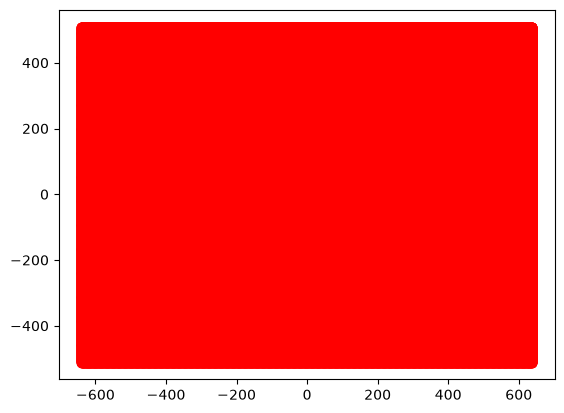

In [3]:
H = 1280 #horizontal pixels - these are not the same as the camera yet so need to be changed
V = 1024 #vertical pixels

x = np.arange(-H/2,H/2-1,1)
y = np.arange(-V/2,V/2-1,1)

xv,yv = np.meshgrid(x,y) #surface area for the hologram - should be similar to that of SLMs resolution

phi = np.angle(xv + 1j * yv, deg=False) #azimuthal angle 
l = 2 #topological charge
# print(phi)
nx = 100 #number of horizontal and vertical grooves
ny = 100

gx = nx/H
gy = nx/V

plt.plot(xv,yv, marker='o', color='r', linestyle='none')
plt.show()

# plt.imshow(x,y)

2. Now that we have made a mesh similar to the size of the SLM screen, we encode a hologram on to it.

[[26.55669855 29.41896948 32.28113662 ... 36.66155161 39.52351048
  42.3855736 ]
 [30.27051784 33.13281212 35.99500251 ... 40.2393105  43.10129238
  45.96337863]
 [33.98444079 36.84675867 39.70897254 ... 43.81696478 46.67896991
  49.54107952]
 [37.69846752 40.56080923 43.42304681 ... 47.39451433 50.25654295
  53.11867616]
 [41.41259815 44.27496392 47.13722545 ... 50.97195905 53.83401139
  56.69616844]]


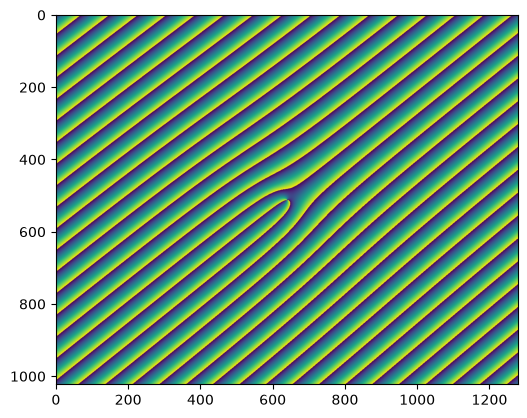

In [4]:
#1. Vortex Beam
zoom = 6
Hol_vortex = np.mod(-l*phi+2*np.pi*(gy*yv/zoom + gx*xv/zoom),2*np.pi) #if I divide the yv and xv in the formula by a factor (it zooms in to the hologram)

#2. Bessel Beam


SLM_vortex = Hol_vortex/np.max(Hol_vortex) * 224 #grayscale normalisation

print(SLM_vortex[:5])
plt.imshow(SLM_vortex)
plt.show()

In [7]:
print(matplotlib.get_backend())

module://matplotlib_inline.backend_inline


3. Plotting the hologram on the second screen (the SLM)

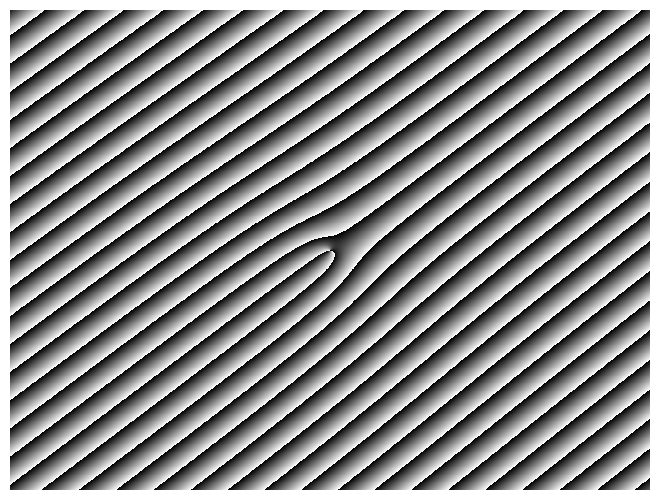

In [5]:
fig = plt.figure(1)

# To access the figure manager
manager = plt.get_current_fig_manager()

# Set window position if supported by the backend
if hasattr(manager, "window"):
    window = manager.window
    if hasattr(window, "wm_geometry"):  # Tkinter
        window.wm_geometry("+1200+0")
    elif hasattr(window, "setGeometry"):  # Qt
        window.setGeometry(1920, 0, 1280, 1024)

# Remove axes margins and display the SLM
ax = fig.add_axes([0, 0, 1, 1])
ax.imshow(SLM_vortex, cmap="gray", interpolation="nearest", aspect="auto")
ax.axis("off")

plt.show()

In [9]:
# # Convert SLM array to 8-bit grayscale
# image = np.asarray(SLM_vortex)

# if image.dtype != np.uint8:
#     image = np.clip(image, 0, 255).astype(np.uint8)

# pil_image = Image.fromarray(image, mode="L")

# # Create a borderless window
# root = tk.Tk()
# root.overrideredirect(True)

# # Set the position to your SLM monitor
# x, y = -300, 0
# root.geometry(f"{image.shape[1]}x{image.shape[0]}+{x}+{y}")

# # Display the image without margins
# photo = ImageTk.PhotoImage(pil_image)
# label = tk.Label(root, image=photo, borderwidth=0)
# label.pack()

# # Press Escape to close the window
# root.bind("<Escape>", lambda event: root.destroy())

# root.mainloop()

In [ ]:
# Check the image
image = np.asarray(SLM_vortex)

print("Image shape:", image.shape)
print("Image dtype:", image.dtype)
print("Image range:", image.min(), image.max())

# Ensure an 8-bit grayscale image
image = np.clip(image, 0, 224).astype(np.uint8)
pil_image = Image.fromarray(image)

# Create display window
root = tk.Tk()
root.overrideredirect(True)
root.attributes("-topmost", True)

height, width = image.shape[:2]

# SLM monitor position
x, y = 1920, 0
root.geometry(f"{width}x{height}+{x}+{y}")

photo = ImageTk.PhotoImage(pil_image)
label = tk.Label(root, image=photo, borderwidth=0, highlightthickness=0)
label.pack()

root.bind("<Escape>", lambda event: root.destroy())

print("Window geometry:", root.geometry())
root.mainloop()

Image shape: (1023, 1279)
Image dtype: float64
Image range: 0.0 224.0
Window geometry: 1x1+1920+0


In [ ]:
from screeninfo import get_monitors

for i, m in enumerate(get_monitors()):
    print(
        f"Monitor {i}: "
        f"x={m.x}, y={m.y}, "
        f"width={m.width}, height={m.height}"
    )

Monitor 0: x=0, y=0, width=1920, height=1080
Monitor 1: x=1920, y=0, width=1280, height=1024


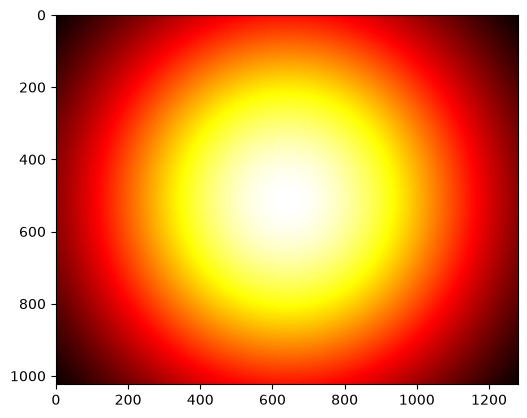

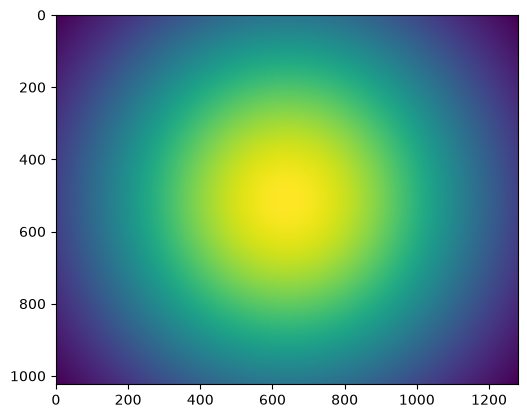

[[0.         1.57079633 3.14159265 ... 1.57079633 3.14159265 4.71238898]
 [0.         1.57079633 3.14159265 ... 1.57079633 3.14159265 4.71238898]
 [0.         1.57079633 3.14159265 ... 1.57079633 3.14159265 4.71238898]
 ...
 [0.         1.57079633 3.14159265 ... 1.57079633 3.14159265 4.71238898]
 [0.         1.57079633 3.14159265 ... 1.57079633 3.14159265 4.71238898]
 [0.         1.57079633 3.14159265 ... 1.57079633 3.14159265 4.71238898]]


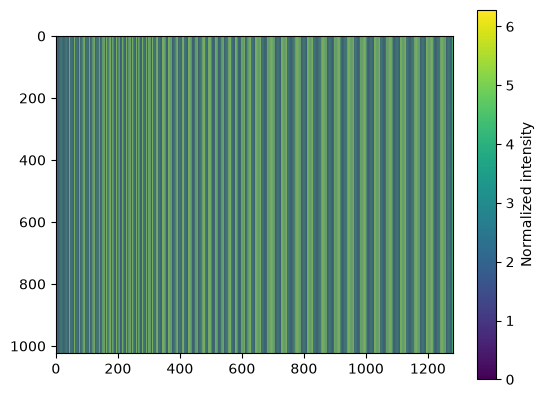

In [6]:
#Defining the input beam
# lambda0 = 520e-9 #nm
# c = 3e8 
# omega = 2*np.pi*c/lambda0

# A0 = 2

# E_in = A0*np.exp(2*np.pi*omega)

Nx, Ny = 1280, 1024

# Beam center (pixels)
x0, y0 = Nx / 2, Ny / 2

w = 600

# Pixel coordinate grids
x = np.arange(Nx)
y = np.arange(Ny)
X,Y = np.meshgrid(x, y)

# Gaussian electric-field amplitude
A_rel = np.exp(-((X-x0)**2 + (Y-y0)**2) / w**2) #max amplitude is at the center 

a = 0.5

# Invert J1(f) = a * A_rel at each point
def g(f, A):
    return j1(f) - a * A

f = np.vectorize(
    lambda A: brentq(g, 0.0, 1.841183781, args=(A,))
)(A_rel)

# print(f)

# Gaussian intensity
I = A_rel**2
I2 = f**2

# Display intensity
plt.imshow(A_rel, cmap="hot", origin="upper")
plt.show()


A_norm = A_rel/np.max(A_rel) * 224

plt.imshow(A_norm)
plt.show()

#Defining phi_relg
period = 4
phi_g = 2 * np.pi * X/period
phi_des = np.zeros((Ny,Nx)) #need to check the shape cuz I had to invert

phi_relg = phi_des + phi_g
phi_relg = np.mod(phi_relg, 2*np.pi)
print(phi_relg)
plt.imshow(phi_relg)
plt.colorbar(label="Normalized intensity")
plt.show()


# # Check the image
# image = np.asarray(I)

# print("Image shape:", image.shape)
# print("Image dtype:", image.dtype)
# print("Image range:", image.min(), image.max())

# # Ensure an 8-bit grayscale image
# image = np.clip(image, 0, 224).astype(np.uint8)
# pil_image = Image.fromarray(image)

# # Create display window
# root = tk.Tk()
# root.overrideredirect(True)
# root.attributes("-topmost", True)

# height, width = image.shape[:2]

# # SLM monitor position
# x, y = 1920, 0
# root.geometry(f"{width}x{height}+{x}+{y}")

# photo = ImageTk.PhotoImage(pil_image)
# label = tk.Label(root, image=photo, borderwidth=0, highlightthickness=0)
# label.pack()

# root.bind("<Escape>", lambda event: root.destroy())

# print("Window geometry:", root.geometry())
# root.mainloop()

(np.float64(-0.5), np.float64(1279.5), np.float64(1023.5), np.float64(-0.5))

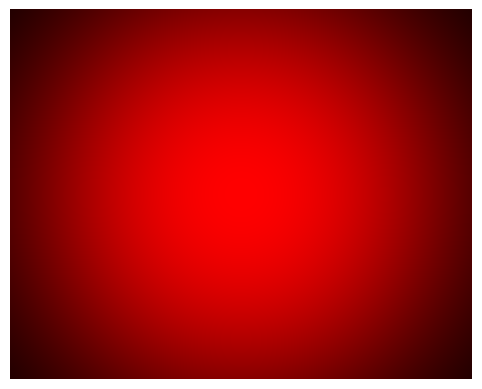

In [9]:
plt.imshow(colorize(A_rel))
plt.gca().axis('off')

[[0.         1.57079633 3.14159265 ... 1.57079633 3.14159265 4.71238898]
 [0.         1.57079633 3.14159265 ... 1.57079633 3.14159265 4.71238898]
 [0.         1.57079633 3.14159265 ... 1.57079633 3.14159265 4.71238898]
 ...
 [0.         1.57079633 3.14159265 ... 1.57079633 3.14159265 4.71238898]
 [0.         1.57079633 3.14159265 ... 1.57079633 3.14159265 4.71238898]
 [0.         1.57079633 3.14159265 ... 1.57079633 3.14159265 4.71238898]]


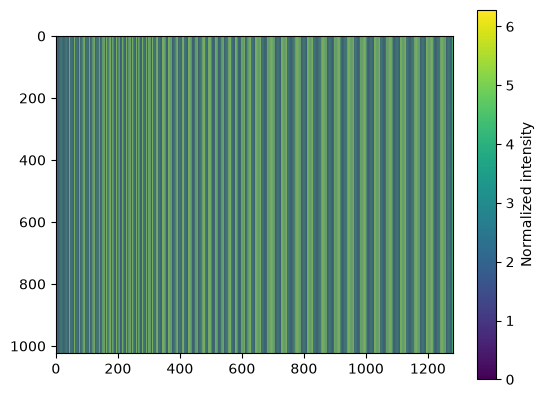

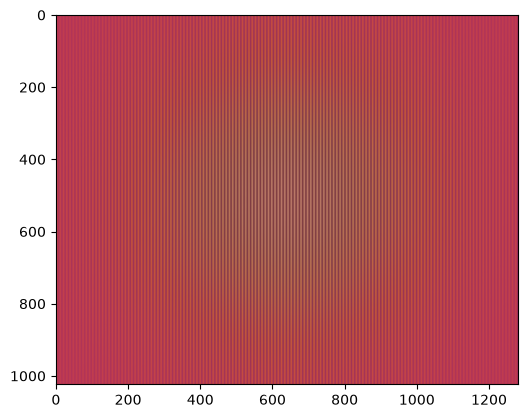

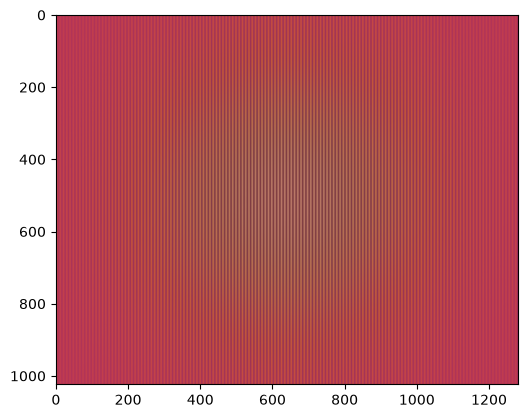

In [ ]:
def hologram(p, Nx, Ny):
    
    

#Defining phi_relg
period = p
phi_g = 2 * np.pi * X/period
phi_des = np.zeros((Ny,Nx)) #need to check the shape cuz I had to invert

phi_relg = phi_des + phi_g
phi_relg = np.mod(phi_relg, 2*np.pi)
print(phi_relg)
plt.imshow(phi_relg)
plt.colorbar(label="Normalized intensity")
plt.show()
#Hologram - Method F

a = 0.5

# Invert J1(f) = a * A_rel at each point
def g(f, A):
    return j1(f) - a * A

f = np.vectorize(
    lambda A: brentq(g, 0.0, 1.841183781, args=(A,))
)(A_rel)

H_F = f * np.sin(phi_relg) #main hologram

plt.imshow(H_F, cmap="inferno")
plt.show()

SLM_H_F = H_F/np.max(H_F) * 224 #grayscale normalisation
plt.imshow(SLM_H_F, cmap="inferno")
plt.show()

return SLM_H_F


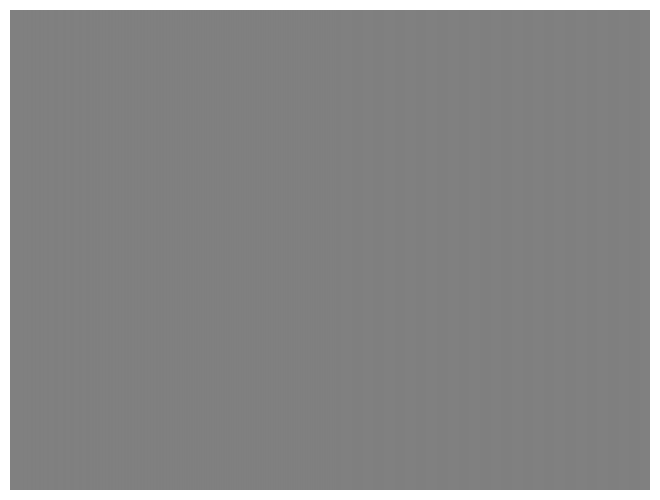

In [23]:
fig = plt.figure(1)

# Get the figure manager
manager = plt.get_current_fig_manager()

# Set window position if supported by the backend
if hasattr(manager, "window"):
    window = manager.window
    if hasattr(window, "wm_geometry"):  # Tkinter
        window.wm_geometry("+1200+0")
    elif hasattr(window, "setGeometry"):  # Qt
        window.setGeometry(1920, 0, 800, 600)

# Remove axes margins and display the SLM
ax = fig.add_axes([0, 0, 1, 1])
ax.imshow(SLM_H_F, cmap="gray", interpolation="nearest", aspect="auto")
ax.axis("off")

plt.show()

In [21]:
E_out = A_rel * np.exp(1j*SLM_H_F)

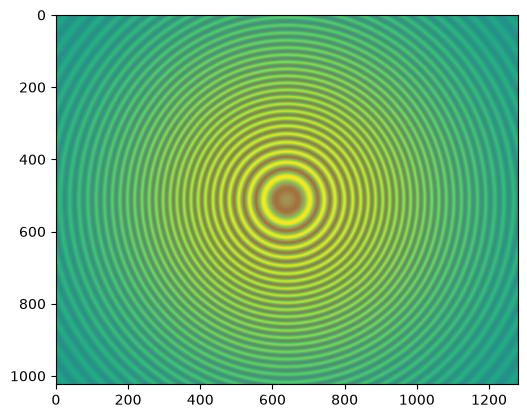

In [22]:
plt.imshow(np.real(E_out))

In [ ]:
image = np.asarray(SLM_H_F)

print("Image shape:", image.shape)
print("Image dtype:", image.dtype)
print("Image range:", image.min(), image.max())

# Ensure an 8-bit grayscale image
image = np.clip(image, 0, 224).astype(np.uint8) #maximum for Hamamatsu for a 2pi modulation
pil_image = Image.fromarray(image)

# Create display window
root = tk.Tk()
root.overrideredirect(True)
root.attributes("-topmost", True)

height, width = image.shape[:2]

# SLM monitor position
x, y = 1920, 0
root.geometry(f"{width}x{height}+{x}+{y}")

photo = ImageTk.PhotoImage(pil_image)
label = tk.Label(root, image=photo, borderwidth=0, highlightthickness=0)
label.pack()

root.bind("<Escape>", lambda event: root.destroy())

print("Window geometry:", root.geometry())
root.mainloop()

Image shape: (1024, 1280)
Image dtype: float64
Image range: -224.0 224.0
Window geometry: 1x1+1920+0


In [ ]:
# nx = 1280
# ny = 1024
# X,Y = np.meshgrid(np.arange(nx)-nx/2, np.arange(ny)-ny/2)
# N = 4
# ell = 2
# hlg_sc = 3 * np.sqrt(N+1) / (Ny)
# L_g = laguerre_gauss(N, ell, hlg_sc*X,hlg_sc*Y)
# L_g = L_g/ np.max(np.abs(L_g))

In [24]:
# plt.imshow(np.abs(L_g))
# plt.show()


In [25]:
# a = 0.5
# # Invert J1(f) = a * A_rel at each point
# def g(f, A):
#     return j1(f) - a * A

# f = np.vectorize(
#     lambda A: brentq(g, 0.0, 1.841183781, args=(A,))
# )(L_g)






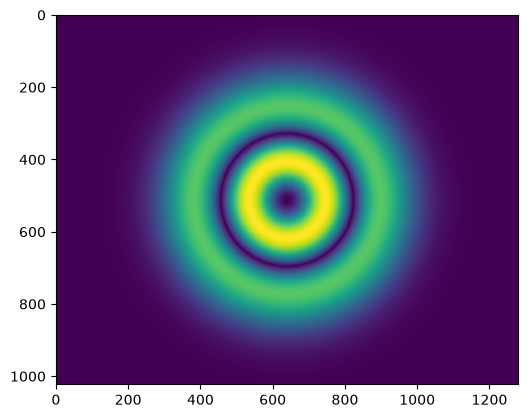

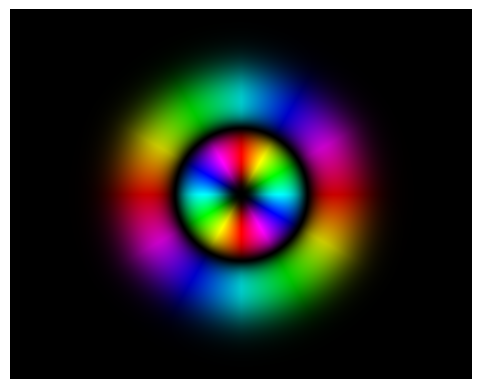

In [19]:
#Laguerre gauss as an input field
N = 4
ell = 2
lg = laguerre_gauss(N, ell, xv/150, yv/150)
plt.imshow(np.abs(lg))
plt.show()

plt.imshow(colorize(lg))
plt.gca().axis('off')
plt.show()

In [ ]:
#For controlling the SLM
slm = slmpy.SLMdisplay()
resX, resY = slm.getSize() #should correspond to the resolution of the native device.

X,Y = np.meshgrid(np.linspace(0,resX,resX),np.linspace(0,resY,resY))
testIMG = np.round((2**8-1)*(0.5+0.5*np.sin(2*np.pi*X/50))).astype('uint8')

slm.updateArray(testIMG)


In [26]:
slm.close() #when finished

NameError: name 'slm' is not defined

In [ ]:
#Testing with different kinds of grids
